# Mid Term Project: Computer Prices

| # | Business Problem | Model |
|---|---|---|
| 1 | Pricing strategy: what price suits a computer, and what drives price? | Linear Regression, Random Forest (regression) |
| 2 | Find overpriced and underpriced computers | Linear Regression (from Problem 1) |
| 3 | Market segments: is a computer Low, Medium or High priced? | Decision Tree (classification) |

**Total models: 3** (2 regression + 1 classification)

## Step 1: Load the data

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

df = pd.read_csv("computer_prices_all.csv")
print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

Rows and columns: (100000, 34)
Missing values: 0
Duplicate rows: 0


,ID,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,...,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,...,2560x1440,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,...,1920x1080,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,...,3440x1440,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99
3,3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,...,3440x1440,120,0,0,650,Wi-Fi 6,5.2,6.00,36,1331.99
4,4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,...,2560x1600,90,80,90,0,Wi-Fi 6,5.2,1.50,12,2681.99


## Step 2: EDA
Two simple checks: how prices are spread, and which columns move together with price.

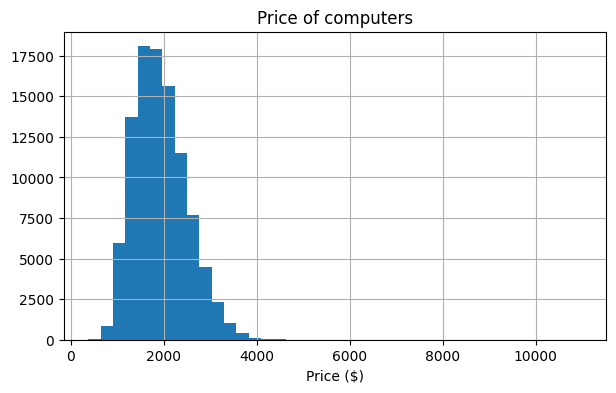

count    100000.0
mean       1929.0
std         580.0
min         373.0
25%        1504.0
50%        1864.0
75%        2288.0
max       10985.0
Name: price, dtype: float64


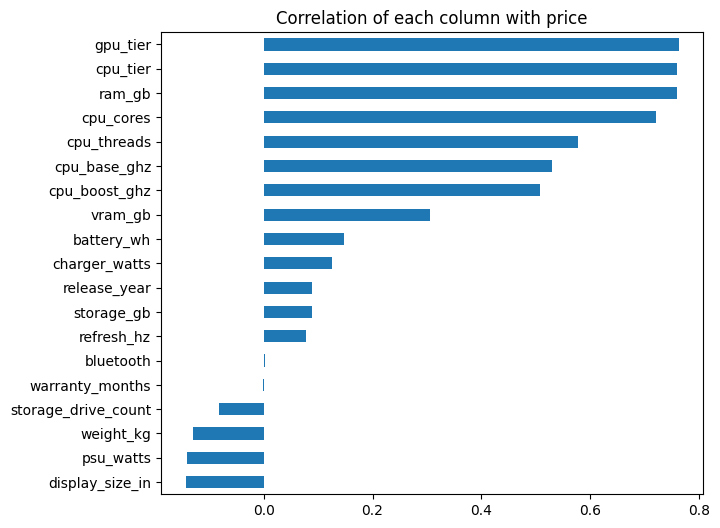

In [29]:
# 1) How are prices spread?
df["price"].hist(bins=40, figsize=(7, 4))
plt.title("Price of computers")
plt.xlabel("Price ($)")
plt.show()
print(df["price"].describe().round(0))


# 2) Which number columns move together with price?
corr = df.select_dtypes("number").drop(columns=["ID"]).corr()["price"].drop("price").sort_values()
corr.plot(kind="barh", figsize=(7, 6))
plt.title("Correlation of each column with price")
plt.show()

**What we see:** most computers cost between about $1,500 and $2,300, and a few are very expensive (up to about $11,000).
RAM, CPU tier and GPU tier have the strongest link with price. These three are also strongly linked with each other, because better computers usually get better of everything.

## Step 3: Data preparation
- Number columns are used as they are.
- Text columns (brand, os, device type, form factor, cpu brand) are changed into 0/1 columns, because models only understand numbers.
- Data is split: 80% for training, 20% for testing.

In [30]:
number_cols = ["release_year", "cpu_tier", "cpu_cores", "cpu_threads",
               "cpu_base_ghz", "cpu_boost_ghz", "gpu_tier", "vram_gb",
               "ram_gb", "storage_gb", "storage_drive_count", "display_size_in",
               "refresh_hz", "battery_wh", "charger_watts", "psu_watts",
               "weight_kg", "warranty_months"]
text_cols = ["device_type", "brand", "os", "form_factor", "cpu_brand"]

X = pd.get_dummies(df[number_cols + text_cols], columns=text_cols)
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 80000
Testing records: 20000


# Problem 1: Pricing Strategy
**Question:** What should a computer cost, and which features push the price up the most?

- **Linear Regression:** learns a straight-line formula between specs and price.
- **Random Forest:** many decision trees that vote together. It also tells which features matter most.
- **MAE** = average mistake in dollars (smaller is better). **R2** = how much of the price the model explains (1.0 is perfect).

In [31]:
# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test) 
print("Linear Regression  MAE:", round(mean_absolute_error(y_test, lr_pred), 2), " R2:", round(r2_score(y_test, lr_pred), 3))

# Model 2: Random Forest
rf = RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest      MAE:", round(mean_absolute_error(y_test, rf_pred), 2), " R2:", round(r2_score(y_test, rf_pred), 3))

Linear Regression  MAE: 201.09  R2: 0.786
Random Forest      MAE: 207.68  R2: 0.766


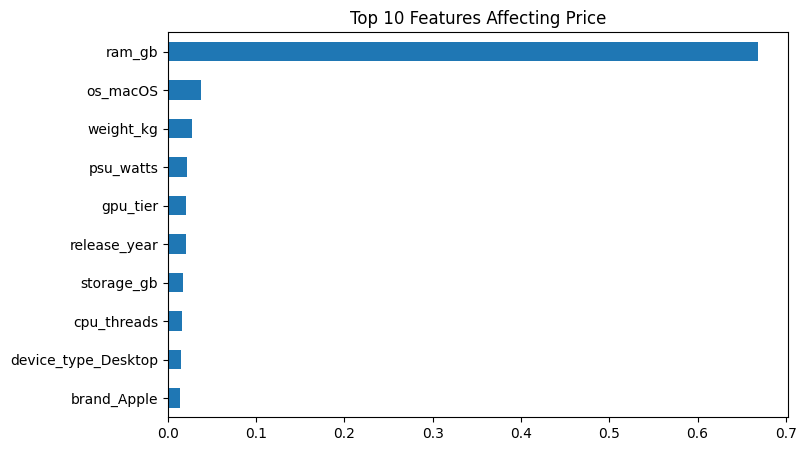

In [32]:
# Which features does the Random Forest use the most?
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Features Affecting Price")
plt.show()

**Conclusion:** Linear Regression (R2 = 0.79, error about $201) scored slightly better than Random Forest (R2 = 0.77, error about $208), so price in this data mostly follows a straight-line pattern with the specs.
Random Forest gives **RAM** the highest importance (about 67%), then macOS, weight, PSU watts and GPU tier. Careful: RAM, CPU tier and GPU tier are strongly linked with each other (correlation about 0.9), so RAM is partly standing in for the overall level of the computer. The safe message is: the overall performance level (RAM together with CPU and GPU) is what drives price. The business should set prices mainly by this level.

# Problem 2: Overpriced / Underpriced Computers
**Question:** Which computers cost much more or much less than their specs suggest?

**Model used:** Linear Regression (best score in Problem 1).
**Idea:** difference = actual price - predicted price. A big positive difference means overpriced, a big negative difference means underpriced.

In [33]:
result = df.loc[X_test.index, ["brand", "model", "price"]].copy()
result["predicted_price"] = lr_pred.round(2)
result["difference"] = (result["price"] - result["predicted_price"]).round(2)

print("Top 5 OVERPRICED:")
print(result.sort_values("difference", ascending=False).head(5))

print()
print("Top 5 UNDERPRICED:")
print(result.sort_values("difference").head(5))

Top 5 OVERPRICED:
          brand              model    price  predicted_price  difference
97808  Gigabyte   Gigabyte Pro XC2  8579.99          2340.46     6239.53
44266      Dell   Dell Stealth MBX  6514.99          1815.75     4699.24
15397      Acer   Acer Creator J3F  5160.99          1720.61     3440.38
87439      Dell     Dell Blade IE0  5031.99          1615.51     3416.48
78468     Apple  Apple Stealth 0C0  5421.99          2407.67     3014.32

Top 5 UNDERPRICED:
      brand             model    price  predicted_price  difference
32504   MSI       MSI Zen 5SI   832.99          2271.71    -1438.72
84237    HP        HP Pro F17   509.99          1858.93    -1348.94
56752  Acer  Acer Stealth D77   605.99          1941.65    -1335.66
49896    HP        HP Pro GKD   636.99          1952.83    -1315.84
88557  Dell      Dell Zen F8V  1256.99          2545.87    -1288.88


**Conclusion:** computers with a big positive difference cost much more than their specs justify (overpriced). Computers with a big negative difference cost far less than their specs suggest (underpriced). The business can lower the price of overpriced ones to sell faster, and consider raising the price of underpriced ones to earn more profit.

# Problem 3: Market Segments
**Question:** What decides if a computer is Low, Medium or High priced?

Prices are divided into 3 equal groups, so random guessing would be right about 33% of the time. The model sees only specs, **not the price**.

**Decision Tree:** asks yes/no questions like "is RAM above 30 GB?" step by step until it decides the segment.

In [34]:
df["segment"] = pd.qcut(df["price"], q=3, labels=["Low", "Medium", "High"])
print(df["segment"].value_counts())

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X, df["segment"], test_size=0.2, random_state=42, stratify=df["segment"])

tree = DecisionTreeClassifier(max_depth=10, random_state=42)
tree.fit(Xs_train, ys_train)
print("Accuracy:", round(accuracy_score(ys_test, tree.predict(Xs_test)), 3), "(random guessing = 0.33)")

segment
Low       33356
Medium    33322
High      33322
Name: count, dtype: int64
Accuracy: 0.723 (random guessing = 0.33)


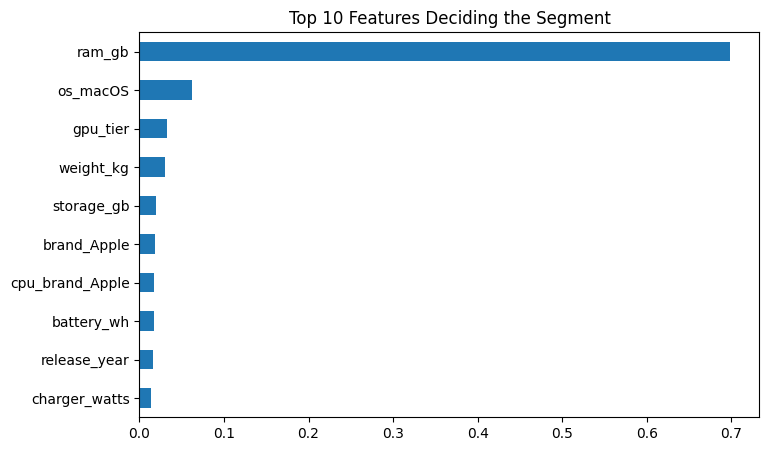

In [35]:
seg_importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values()
seg_importance.tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Features Deciding the Segment")
plt.show()

**Conclusion:** the Decision Tree puts a computer in the correct price segment about 72% of the time using specs only, which is much better than random guessing (33%). RAM is again the most important feature (about 70%), followed by macOS, GPU tier and weight. The same warning applies: RAM is linked with CPU and GPU tier. A business can use this to plan budget, mid-range and premium products.

In [36]:
from sklearn.metrics import confusion_matrix, classification_report

# Predictions
ys_pred = tree.predict(Xs_test)

# Accuracy
print("Accuracy:", round(accuracy_score(ys_test, ys_pred), 4))

# Classification Report
print("\nClassification Report:")
print(classification_report(ys_test, ys_pred))

Accuracy: 0.7226

Classification Report:
              precision    recall  f1-score   support

        High       0.80      0.78      0.79      6665
         Low       0.78      0.79      0.78      6671
      Medium       0.59      0.60      0.59      6664

    accuracy                           0.72     20000
   macro avg       0.72      0.72      0.72     20000
weighted avg       0.72      0.72      0.72     20000



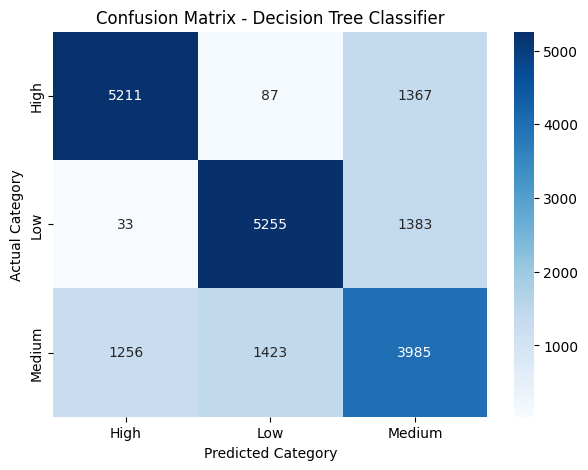

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix
cm = confusion_matrix(ys_test, ys_pred)

# Plot Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["High", "Low", "Medium"],
    yticklabels=["High", "Low", "Medium"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix - Decision Tree Classifier")
plt.show()

# Conclusion
- **Problem 1:** Linear Regression (R2 0.79) and Random Forest (R2 0.77) both explain price well. The overall performance level, mainly RAM together with CPU and GPU, drives price.
- **Problem 2:** Comparing actual price with predicted price finds overpriced and underpriced computers, which helps in pricing decisions.
- **Problem 3:** The Decision Tree separates Low, Medium and High segments with about 72% accuracy (random guess is 33%).
